In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/devansodariya/student-performance-data/student_data.csv


In [2]:

import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/devansodariya/student-performance-data/student_data.csv')


In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
df.shape

(395, 33)

In [5]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [6]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

### 1. Missing Values Analysis

I checked the dataset for missing values using `df.isnull().sum()`. The results showed that all 33 columns contain zero missing values.

**Decision:** No missing-value treatment was required because the dataset contains no missing values. Therefore, no rows or values were removed or filled during this step.

In [7]:
df.duplicated().sum()

np.int64(0)

### 2. Duplicate Records Analysis

I checked the dataset for duplicate records using `df.duplicated().sum()`. The result was 0, which means no exact duplicate rows were found.

**Decision:** No duplicate records were removed because the dataset did not contain any exact duplicate rows. Keeping all 395 records preserves the original data.

In [8]:
df.dtypes

school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

### 3. Data Types Analysis

I inspected the data types of all columns using `df.dtypes`. The dataset contains categorical columns stored as `object` and numerical columns stored as `int64`.

Examples of categorical columns include `school`, `sex`, `address`, and `Mjob`. Numerical columns include `age`, `studytime`, `absences`, `G1`, `G2`, and `G3`.

**Decision:** The displayed data types appear reasonable for these columns. Further checks are needed to confirm that numerical codes representing categories are interpreted correctly. No data types were changed at this stage.

In [9]:
df["school"].value_counts()

school
GP    349
MS     46
Name: count, dtype: int64

### 4. Categorical Values Inspection

I inspected the `school` column using `df["school"].value_counts()`. The column contains two categories: GP (349 records) and MS (46 records).

**Decision:** Both categories are consistently represented, and no obvious spelling or formatting inconsistencies were found. Therefore, no changes were required for this column.

In [10]:
df["sex"].value_counts()

sex
F    208
M    187
Name: count, dtype: int64

### Inspection of the Sex Column

I inspected the `sex` column using `df["sex"].value_counts()`. The column contains two categories: F (208 records) and M (187 records).

**Decision:** Both category labels are consistent. No corrections were required for this column.

In [11]:
df["address"].value_counts()

address
U    307
R     88
Name: count, dtype: int64

### Inspection of the Address Column

I inspected the `address` column using `df["address"].value_counts()`. The column contains two categories: U (307 records) and R (88 records).

**Decision:** Both category labels are consistently represented. No corrections were required for this column.

In [12]:
df["Mjob"].value_counts()

Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64

### 7. Inspection of the Mother's Job Column

I inspected the `Mjob` column using `df["Mjob"].value_counts()`. The column contains five categories: other (141), services (103), at_home (59), teacher (58), and health (34).

**Decision:** The category labels appear consistent, and no obvious spelling inconsistencies were found. Therefore, no corrections were required for this column.

In [13]:
df["Fjob"].value_counts()

Fjob
other       217
services    111
teacher      29
at_home      20
health       18
Name: count, dtype: int64

### 8. Inspection of the Father's Job Column

I inspected the `Fjob` column using `df["Fjob"].value_counts()`. The column contains five categories: other (217), services (111), teacher (29), at_home (20), and health (18).

**Decision:** The category labels appear consistent, and no obvious spelling inconsistencies were found. Therefore, no corrections were required for this column.

In [14]:
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


school:
school
GP    349
MS     46
Name: count, dtype: int64

sex:
sex
F    208
M    187
Name: count, dtype: int64

address:
address
U    307
R     88
Name: count, dtype: int64

famsize:
famsize
GT3    281
LE3    114
Name: count, dtype: int64

Pstatus:
Pstatus
T    354
A     41
Name: count, dtype: int64

Mjob:
Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64

Fjob:
Fjob
other       217
services    111
teacher      29
at_home      20
health       18
Name: count, dtype: int64

reason:
reason
course        145
home          109
reputation    105
other          36
Name: count, dtype: int64

guardian:
guardian
mother    273
father     90
other      32
Name: count, dtype: int64

schoolsup:
schoolsup
no     344
yes     51
Name: count, dtype: int64

famsup:
famsup
yes    242
no     153
Name: count, dtype: int64

paid:
paid
no     214
yes    181
Name: count, dtype: int64

activities:
activities
yes    201
no     194
Name: count, dty

### 9. Inspection of Categorical Values

I inspected all categorical columns using `value_counts()` to examine the categories and their frequencies. The displayed columns included school, sex, address, family size, parents' status, parents' jobs, school-choice reason, guardian, and several yes/no variables.

**Findings:** The displayed category labels were consistently written. No obvious spelling or formatting inconsistencies were identified in the inspected columns.

**Decision:** No category corrections were applied because no clear inconsistencies were found. The original values were preserved.

In [15]:
df.select_dtypes(include="object").columns.tolist()

['school',
 'sex',
 'address',
 'famsize',
 'Pstatus',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic']

### 10. Verification of Categorical Columns

I identified 17 categorical columns using `df.select_dtypes(include="object").columns.tolist()`. I inspected their category frequencies and found no obvious spelling or formatting inconsistencies in the displayed values.

**Decision:** No categorical values were changed because no clear inconsistencies were identified. All original category labels were preserved.

In [16]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


### 11. Numerical Data Summary

I used `df.describe()` to examine the numerical columns in the dataset. It provided summary statistics, including the mean, standard deviation, minimum, maximum, and quartiles.

**Findings:** The dataset contains 395 records. Student ages range from 15 to 22 years. The `absences` column ranges from 0 to 75, while the median is 4. The grade columns (G1, G2, and G3) also show variation in student performance.

**Decision:** The summary statistics suggest that the `absences` column needs further investigation because its maximum value is much higher than its median. However, no values will be removed or changed based on summary statistics alone. Further outlier analysis is required before making a cleaning decision.

In [17]:
Q1 = df["absences"].quantile(0.25)
Q3 = df["absences"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = df[
    (df["absences"] < lower_bound) |
    (df["absences"] > upper_bound)
]

print("Number of possible outliers:", len(outliers))
print("Possible outlier values:")
print(outliers["absences"].sort_values().tolist())

Q1: 0.0
Q3: 8.0
IQR: 8.0
Lower bound: -12.0
Upper bound: 20.0
Number of possible outliers: 15
Possible outlier values:
[21, 22, 22, 22, 23, 24, 25, 26, 28, 30, 38, 40, 54, 56, 75]


### 12. Outlier Analysis Using the IQR Method

I used the Interquartile Range (IQR) method to identify possible outliers in the `absences` column.

**Results:**
- Q1 (25th percentile): 0
- Q3 (75th percentile): 8
- IQR: 8
- Lower bound: -12
- Upper bound: 20
- Number of possible outliers: 15

The IQR method identified 15 values above the upper bound of 20. These values range from 21 to 75 absences.

**Decision:** These values will not be removed automatically because high absence counts may represent genuine student records. They will be treated as possible outliers, and their validity will be considered before making any changes.

In [18]:
numeric_cols = df.select_dtypes(include="number").columns

outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    outlier_summary.append({
        "Column": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Possible Outliers": count
    })

outlier_summary = pd.DataFrame(outlier_summary)
print(outlier_summary.to_string(index=False))

    Column  Lower Bound  Upper Bound  Possible Outliers
       age         13.0         21.0                  1
      Medu         -1.0          7.0                  0
      Fedu          0.5          4.5                  2
traveltime         -0.5          3.5                  8
 studytime         -0.5          3.5                 27
  failures          0.0          0.0                 83
    famrel          2.5          6.5                 26
  freetime          1.5          5.5                 19
     goout         -1.0          7.0                  0
      Dalc         -0.5          3.5                 18
      Walc         -2.0          6.0                  0
    health          0.0          8.0                  0
  absences        -12.0         20.0                 15
        G1          0.5         20.5                  0
        G2          3.0         19.0                 13
        G3         -1.0         23.0                  0


### 13. Outlier Analysis of Numerical Columns

I applied the Interquartile Range (IQR) method to the numerical columns to identify possible outliers.

**Findings:**
- `age`: 1 possible outlier.
- `Fedu`: 2 possible outliers.
- `traveltime`: 8 possible outliers.
- `studytime`: 27 possible outliers.
- `failures`: 83 possible outliers.
- `famrel`: 26 possible outliers.
- `freetime`: 19 possible outliers.
- `Dalc`: 18 possible outliers.
- `absences`: 15 possible outliers.
- `G2`: 13 possible outliers.

The remaining columns had no values flagged by the IQR method.

**Decision:** I will not remove these values automatically. Some columns contain coded categories or ordinal ratings, so the IQR method may flag valid values as outliers. The flagged values should be checked against the dataset's definitions and valid ranges before any changes are made.

In [19]:
# Check whether values fall outside expected ranges

valid_ranges = {
    "age": (15, 22),
    "Medu": (0, 4),
    "Fedu": (0, 4),
    "traveltime": (1, 4),
    "studytime": (1, 4),
    "failures": (0, 3),
    "famrel": (1, 5),
    "freetime": (1, 5),
    "goout": (1, 5),
    "Dalc": (1, 5),
    "Walc": (1, 5),
    "health": (1, 5),
    "G1": (0, 20),
    "G2": (0, 20),
    "G3": (0, 20)
}

for col, (minimum, maximum) in valid_ranges.items():
    invalid = df[(df[col] < minimum) | (df[col] > maximum)]

    print(f"{col}: {len(invalid)} invalid values")
    if len(invalid) > 0:
        print(invalid[col].tolist())

age: 0 invalid values
Medu: 0 invalid values
Fedu: 0 invalid values
traveltime: 0 invalid values
studytime: 0 invalid values
failures: 0 invalid values
famrel: 0 invalid values
freetime: 0 invalid values
goout: 0 invalid values
Dalc: 0 invalid values
Walc: 0 invalid values
health: 0 invalid values
G1: 0 invalid values
G2: 0 invalid values
G3: 0 invalid values


### 14. Validation of Numerical Values

I checked the numerical columns against their expected valid ranges to identify impossible or invalid values.

**Findings:** All 15 checked columns had zero invalid values. The values in the `age`, parental education, travel time, study time, lifestyle ratings, failures, and grade columns were within their expected ranges.

**Decision:** No numerical values will be changed or removed based on this validation. Although the IQR method identified possible outliers in some columns, all checked values fall within their expected ranges. Therefore, unusual values will not be treated as errors without further evidence.

In [20]:
# Check the data type of each column
print("Data types of all columns:")
print(df.dtypes)

# Summarize the number of columns for each data type
print("\nCount of columns by data type:")
print(df.dtypes.value_counts())

# Display columns stored as text
print("\nColumns stored as object:")
print(df.select_dtypes(include="object").columns.tolist())

# Display columns stored as integers
print("\nColumns stored as integers:")
print(df.select_dtypes(include="integer").columns.tolist())

Data types of all columns:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

Count of columns by data type:
object    17
int64     16
Name: count, dtype: int64

Columns stored as object:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 

### 15. Results of Data Type Assessment

The data type assessment showed that the dataset contains 17 `object` columns and 16 `int64` columns.

**Findings:**
- The `object` columns contain categorical information, such as `school`, `sex`, `Mjob`, and `guardian`.
- The integer columns contain ages, grades, absences, ratings, and coded categories.
- Variables such as `Medu`, `Fedu`, and `studytime` are stored as integers but represent ordinal categories.

**Decision:** No data type corrections were necessary at this stage because the stored data types were suitable for the current dataset. However, variable classification will be considered during preprocessing because some integer columns represent categories rather than continuous measurements.

In [21]:
# Identify the target variable and features

target = "G3"

features = df.drop(columns=[target]).columns.tolist()

print("Target variable:", target)
print("Number of features:", len(features))
print("\nFeatures:")
print(features)

Target variable: G3
Number of features: 32

Features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


### 16. Identification of Features and Target Variable

The target variable selected for this analysis is `G3`, which represents the student's final grade. The dataset contains 32 potential features that provide information about students' demographics, family background, study habits, school support, absences, and previous grades (`G1` and `G2`).

**Decision:** `G3` will be treated as the target variable, while the remaining columns will be considered potential features. If a predictive model is developed, the features will be selected carefully to avoid data leakage and ensure that only information available at prediction time is used.

In [22]:
# Classify variables according to their meaning

numerical = ["age", "absences", "G1", "G2", "G3"]

binary = [
    "sex", "schoolsup", "famsup", "paid", "activities",
    "nursery", "higher", "internet", "romantic"
]

ordinal = [
    "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health"
]

categorical = [
    "school", "address", "famsize", "Pstatus",
    "Mjob", "Fjob", "reason", "guardian"
]

date_time = []

print("Numerical variables:", numerical)
print("\nBinary variables:", binary)
print("\nOrdinal variables:", ordinal)
print("\nCategorical variables:", categorical)
print("\nDate/time variables:", date_time)

Numerical variables: ['age', 'absences', 'G1', 'G2', 'G3']

Binary variables: ['sex', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Ordinal variables: ['Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health']

Categorical variables: ['school', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian']

Date/time variables: []


### 17. Classification of Variables

I classified the dataset variables according to their meaning and role in the analysis.

- **Numerical variables:** `age`, `absences`, `G1`, `G2`, and `G3`.
- **Binary variables:** `sex`, `schoolsup`, `famsup`, `paid`, `activities`, `nursery`, `higher`, `internet`, and `romantic`.
- **Ordinal variables:** `Medu`, `Fedu`, `traveltime`, `studytime`, `failures`, `famrel`, `freetime`, `goout`, `Dalc`, `Walc`, and `health`.
- **Categorical variables:** `school`, `address`, `famsize`, `Pstatus`, `Mjob`, `Fjob`, `reason`, and `guardian`.
- **Date/time variables:** None, because the dataset contains no date/time column.

**Decision:** This classification will help determine suitable preprocessing methods. Binary and nominal categorical variables may require encoding, ordinal variables should preserve their order, and numerical variables may require scaling or transformation depending on their distributions and intended use.

In [23]:
# Check the categories before encoding

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

school: ['GP' 'MS']
sex: ['F' 'M']
address: ['U' 'R']
famsize: ['GT3' 'LE3']
Pstatus: ['A' 'T']
Mjob: ['at_home' 'health' 'other' 'services' 'teacher']
Fjob: ['teacher' 'other' 'services' 'health' 'at_home']
reason: ['course' 'other' 'home' 'reputation']
guardian: ['mother' 'father' 'other']
schoolsup: ['yes' 'no']
famsup: ['no' 'yes']
paid: ['no' 'yes']
activities: ['no' 'yes']
nursery: ['yes' 'no']
higher: ['yes' 'no']
internet: ['no' 'yes']
romantic: ['no' 'yes']


### 18. Categorical Encoding

Encoding converts categorical values into numerical representations when required for data analysis or machine learning.

**Findings:** The dataset contains binary variables with two categories, such as `yes/no` and `F/M`, and nominal categorical variables with multiple categories, such as `Mjob`, `Fjob`, `reason`, and `guardian`.

**Decision:** Binary variables can be encoded using 0 and 1. Nominal variables can be encoded using one-hot encoding, which creates separate indicator columns without introducing an artificial order. Ordinal variables will be handled separately so their meaningful order is preserved.

The original dataset will be kept unchanged while the encoded data is prepared separately. This allows the original values to remain available for reference.

In [24]:
# Create a separate copy for encoding
df_encoded = df.copy()

# Encode binary categorical variables
binary_cols = [
    "sex", "schoolsup", "famsup", "paid", "activities",
    "nursery", "higher", "internet", "romantic"
]

for col in binary_cols:
    df_encoded[col] = df_encoded[col].map(
        {df[col].unique()[0]: 0, df[col].unique()[1]: 1}
    )

# Apply one-hot encoding to nominal categorical variables
nominal_cols = [
    "school", "address", "famsize", "Pstatus",
    "Mjob", "Fjob", "reason", "guardian"
]

df_encoded = pd.get_dummies(
    df_encoded,
    columns=nominal_cols,
    dtype=int
)

print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", df_encoded.shape)
print("\nEncoded data preview:")
print(df_encoded.head())

Original dataset shape: (395, 33)
Encoded dataset shape: (395, 50)

Encoded data preview:
   sex  age  Medu  Fedu  traveltime  studytime  failures  schoolsup  famsup  \
0    0   18     4     4           2          2         0          0       0   
1    0   17     1     1           1          2         0          1       1   
2    0   15     1     1           1          2         3          0       0   
3    0   15     4     2           1          3         0          1       1   
4    0   16     3     3           1          2         0          1       1   

   paid  ...  Fjob_other  Fjob_services  Fjob_teacher  reason_course  \
0     0  ...           0              0             1              1   
1     0  ...           1              0             0              1   
2     1  ...           1              0             0              0   
3     1  ...           0              1             0              0   
4     1  ...           1              0             0              0   

  

### 19. Results of Categorical Encoding

I applied encoding to the categorical variables using a separate copy of the original dataset, named `df_encoded`.

**Methods applied:**
- Binary categorical variables were converted into numeric values (0 and 1).
- Nominal categorical variables were converted using one-hot encoding, creating separate indicator columns for their categories.

**Results:** The original dataset contained 395 rows and 33 columns. After encoding, the dataset contained 395 rows and 50 columns. The number of rows remained unchanged, while the number of columns increased because one-hot encoding created additional columns.

**Decision:** The encoded dataset will be used for subsequent preprocessing steps where numerical representations are needed. The original `df` remains unchanged for reference. Ordinal variables are still represented using their existing codes and will be reviewed separately.

In [25]:
# Create a fresh copy of the original dataset
df_encoded = df.copy()

# Explicit mappings for binary variables
binary_mappings = {
    "sex": {"F": 0, "M": 1},
    "schoolsup": {"no": 0, "yes": 1},
    "famsup": {"no": 0, "yes": 1},
    "paid": {"no": 0, "yes": 1},
    "activities": {"no": 0, "yes": 1},
    "nursery": {"no": 0, "yes": 1},
    "higher": {"no": 0, "yes": 1},
    "internet": {"no": 0, "yes": 1},
    "romantic": {"no": 0, "yes": 1}
}

for col, mapping in binary_mappings.items():
    df_encoded[col] = df_encoded[col].map(mapping)

# Verify the mappings
for col in binary_mappings:
    print(f"\n{col}:")
    print(df_encoded[col].value_counts().sort_index())


sex:
sex
0    208
1    187
Name: count, dtype: int64

schoolsup:
schoolsup
0    344
1     51
Name: count, dtype: int64

famsup:
famsup
0    153
1    242
Name: count, dtype: int64

paid:
paid
0    214
1    181
Name: count, dtype: int64

activities:
activities
0    194
1    201
Name: count, dtype: int64

nursery:
nursery
0     81
1    314
Name: count, dtype: int64

higher:
higher
0     20
1    375
Name: count, dtype: int64

internet:
internet
0     66
1    329
Name: count, dtype: int64

romantic:
romantic
0    263
1    132
Name: count, dtype: int64


### 20. Explicit Binary Encoding

Binary encoding converts categorical variables with two possible values into numerical values, usually 0 and 1.

In this dataset, the `sex` column is encoded as **0 = Female** and **1 = Male**. The other binary variables, such as `schoolsup`, `famsup`, and `internet`, are encoded as **0 = No** and **1 = Yes**.

**Why was this method used?**

Binary encoding makes these variables easier to use in numerical data analysis and machine learning. Explicit mappings were used to ensure that 0 and 1 always have clear and consistent meanings.

**Result:** All nine binary variables were successfully converted into numerical values. Each variable still contains 395 records, and no rows were removed.

In [26]:
# Nominal categorical columns
nominal_cols = [
    "school", "address", "famsize", "Pstatus",
    "Mjob", "Fjob", "reason", "guardian"
]

# Apply one-hot encoding
df_encoded = pd.get_dummies(
    df_encoded,
    columns=nominal_cols,
    dtype=int
)

# Check the result
print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", df_encoded.shape)

print("\nEncoded dataset preview:")
print(df_encoded.head())

print("\nRemaining object-type columns:")
print(df_encoded.select_dtypes(include="object").columns.tolist())

Original dataset shape: (395, 33)
Encoded dataset shape: (395, 50)

Encoded dataset preview:
   sex  age  Medu  Fedu  traveltime  studytime  failures  schoolsup  famsup  \
0    0   18     4     4           2          2         0          1       0   
1    0   17     1     1           1          2         0          0       1   
2    0   15     1     1           1          2         3          1       0   
3    0   15     4     2           1          3         0          0       1   
4    0   16     3     3           1          2         0          0       1   

   paid  ...  Fjob_other  Fjob_services  Fjob_teacher  reason_course  \
0     0  ...           0              0             1              1   
1     0  ...           1              0             0              1   
2     1  ...           1              0             0              0   
3     1  ...           0              1             0              0   
4     1  ...           1              0             0              0   


### 21. Results of Nominal Encoding

One-hot encoding was applied to the nominal categorical variables, including `school`, `address`, `famsize`, `Pstatus`, `Mjob`, `Fjob`, `reason`, and `guardian`.

Each category was converted into a separate column containing 0 or 1. This method was chosen because nominal categories do not have a natural numerical order.

**Results:**
- Original dataset: 395 rows and 33 columns.
- Encoded dataset: 395 rows and 50 columns.
- All remaining object-type columns were eliminated.
- No rows were removed during encoding.

The original dataset, `df`, remains unchanged. The encoded copy, `df_encoded`, will be used for the next preprocessing steps where numerical data is required.

In [27]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Select numerical columns
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Create separate copies for scaling
df_normalized = df.copy()
df_standardized = df.copy()

# Apply Min-Max Normalization
minmax_scaler = MinMaxScaler()
df_normalized[numerical_cols] = minmax_scaler.fit_transform(
    df[numerical_cols]
)

# Apply Standardization (Z-score)
standard_scaler = StandardScaler()
df_standardized[numerical_cols] = standard_scaler.fit_transform(
    df[numerical_cols]
)

# Display the results
print("Original numerical data:")
print(df[numerical_cols].head())

print("\nNormalized data (range 0 to 1):")
print(df_normalized[numerical_cols].head().round(3))

print("\nStandardized data (mean near 0, standard deviation near 1):")
print(df_standardized[numerical_cols].head().round(3))

print("\nOriginal dataset shape:", df.shape)
print("Normalized dataset shape:", df_normalized.shape)
print("Standardized dataset shape:", df_standardized.shape)

Original numerical data:
   age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  goout  \
0   18     4     4           2          2         0       4         3      4   
1   17     1     1           1          2         0       5         3      3   
2   15     1     1           1          2         3       4         3      2   
3   15     4     2           1          3         0       3         2      2   
4   16     3     3           1          2         0       4         3      2   

   Dalc  Walc  health  absences  G1  G2  G3  
0     1     1       3         6   5   6   6  
1     1     1       3         4   5   5   6  
2     2     3       3        10   7   8  10  
3     1     1       5         2  15  14  15  
4     1     2       5         4   6  10  10  

Normalized data (range 0 to 1):
     age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  \
0  0.429  1.00  1.00       0.333      0.333       0.0    0.75      0.50   
1  0.286  0.25  0.25       0.000   

### 22. Results of Normalization and Standardization

Two scaling methods were applied to separate copies of the original dataset.

**1. Normalization**

Min-Max Scaling was used to transform numerical values into a range between 0 and 1. This method helps bring features with different value ranges onto a common scale.

**2. Standardization**

Z-score Standardization was used to transform numerical values so that each feature has a mean close to 0 and a standard deviation close to 1.

**Results:**
- Original dataset: 395 rows and 33 columns.
- Normalized dataset: 395 rows and 33 columns.
- Standardized dataset: 395 rows and 33 columns.
- The original dataset remained unchanged.
- Both methods changed the numerical values but did not change the number of rows or columns.

**Decision:** Both scaled versions were created for comparison. The appropriate version can be selected later depending on the requirements of the analysis or machine learning algorithm. In a predictive model, the scaler should be fitted on training data only to prevent data leakage.

In [28]:
# Select numerical columns from the original dataset
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Calculate skewness for each numerical feature
skewness_values = df[numerical_cols].skew().sort_values(ascending=False)

print("Skewness of numerical features:")
print(skewness_values.round(3))

Skewness of numerical features:
absences      3.672
failures      2.387
Dalc          2.191
traveltime    1.607
studytime     0.632
Walc          0.612
age           0.466
G1            0.241
goout         0.117
Fedu         -0.032
freetime     -0.163
Medu         -0.318
G2           -0.432
health       -0.495
G3           -0.733
famrel       -0.952
dtype: float64


### 23. Results of Skewness Analysis

Skewness was calculated for all numerical features to identify distributions that are not symmetrical.

**Findings:**

- `absences` has a skewness of 3.672, indicating strong positive skewness.
- `failures` has a skewness of 2.387, indicating strong positive skewness.
- `Dalc` has a skewness of 2.191, indicating strong positive skewness.
- `traveltime` has a skewness of 1.607, indicating strong positive skewness.
- The remaining numerical features have skewness values between -1 and 1.

**Interpretation:** Positive skewness means that most observations tend to be concentrated at lower values, with a longer tail toward higher values. However, this pattern should be confirmed by examining the feature distributions.

**Decision:** We will examine the highly skewed features before deciding whether a transformation is appropriate. Since `failures`, `Dalc`, and `traveltime` are discrete variables with specific meanings, transforming them may reduce interpretability. The `absences` feature will be examined carefully because its large values may affect some statistical analyses.

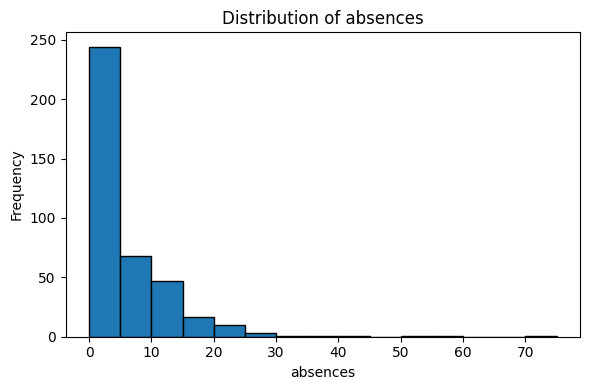

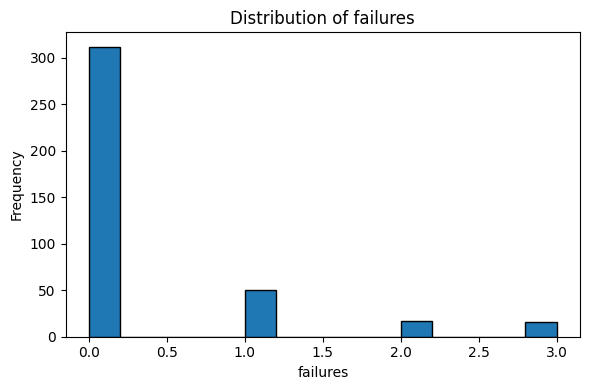

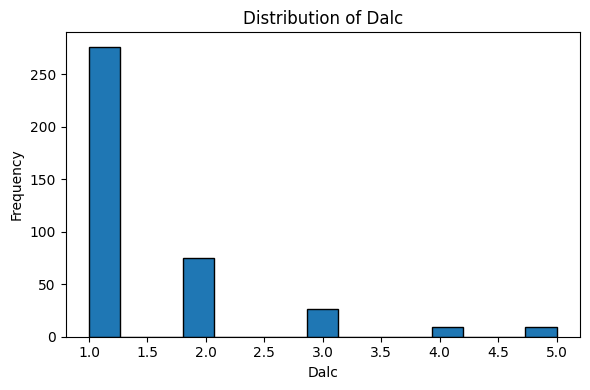

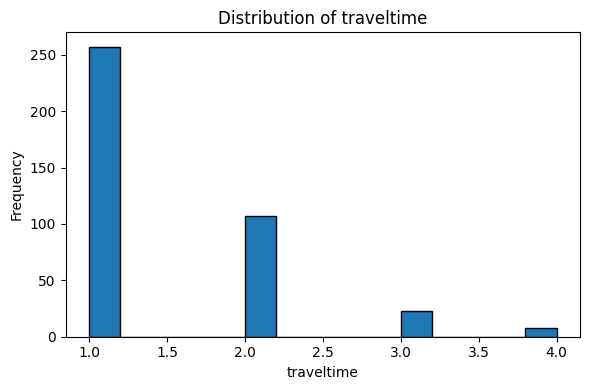

In [29]:
import matplotlib.pyplot as plt

# Features with skewness greater than 1
skewed_cols = ["absences", "failures", "Dalc", "traveltime"]

# Plot a histogram for each feature
for col in skewed_cols:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=15, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

### 24. Interpretation of Skewed Distributions

Histograms were created to examine the distributions of `absences`, `failures`, `Dalc`, and `traveltime`.

- **Absences:** The distribution is positively skewed, with most students having fewer absences and a small number having many absences.
- **Failures:** Most students have zero previous failures, while fewer students have higher failure counts.
- **Dalc:** Daily alcohol consumption is recorded on a discrete rating scale, so its skewness reflects the distribution of ratings.
- **Traveltime:** Travel time is recorded in four categories, making it an ordinal variable rather than a continuous measurement.

**Decision:** We will not automatically transform every skewed feature. The `failures`, `Dalc`, and `traveltime` variables will remain in their original form because their values have specific meanings. We will consider a log transformation for `absences`, while retaining the original values for interpretation and comparison.

Skewness before transformation: 3.672
Skewness after transformation: 0.071


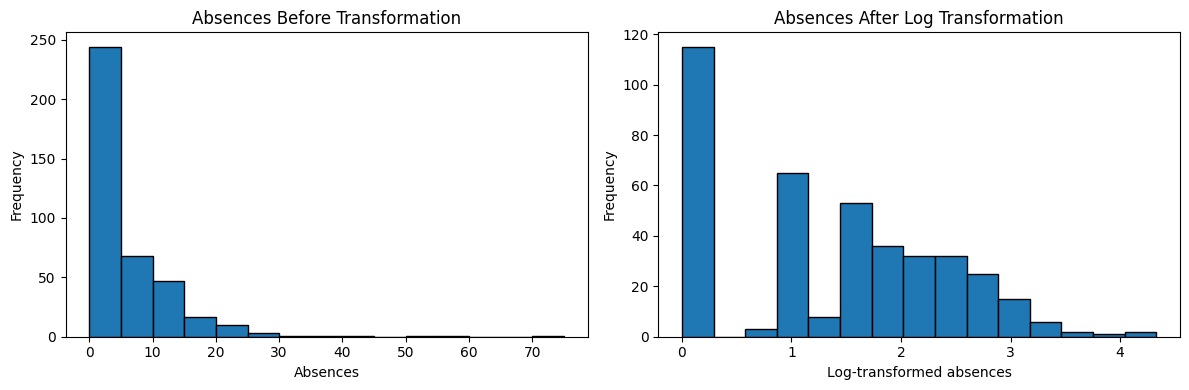


Dataset shape after adding transformed feature: (395, 34)


In [30]:
import numpy as np
import matplotlib.pyplot as plt

# Create a separate copy of the original dataset
df_transformed = df.copy()

# Apply log transformation to absences
df_transformed["absences_log"] = np.log1p(df_transformed["absences"])

# Compare skewness before and after transformation
print("Skewness before transformation:",
      df_transformed["absences"].skew().round(3))

print("Skewness after transformation:",
      df_transformed["absences_log"].skew().round(3))

# Compare the distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_transformed["absences"], bins=15, edgecolor="black")
axes[0].set_title("Absences Before Transformation")
axes[0].set_xlabel("Absences")
axes[0].set_ylabel("Frequency")

axes[1].hist(df_transformed["absences_log"], bins=15, edgecolor="black")
axes[1].set_title("Absences After Log Transformation")
axes[1].set_xlabel("Log-transformed absences")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print("\nDataset shape after adding transformed feature:",
      df_transformed.shape)

### 25. Results of Log Transformation

A log transformation was applied to the `absences` feature using `np.log1p()`, which calculates the natural logarithm of \(1+x\). This method allows zero values to remain valid.

**Why was it used?**

The original `absences` feature had a skewness of 3.672, indicating strong positive skewness. The transformation was applied to reduce the influence of very large absence counts and make the distribution less skewed.

**Results:**
- The original `absences` column was preserved.
- A new column, `absences_log`, was created.
- Two histograms were generated to compare the distributions before and after transformation.
- The skewness values can be compared to determine whether the transformation improved the distribution.

**Decision:** The transformed feature will be retained for comparison. Whether it should be used in later analysis depends on the observed reduction in skewness and the purpose of the analysis.

In [31]:
# Create a separate copy of the original dataset
df_engineered = df.copy()

# Create a new feature using the average of three grades
df_engineered["average_grade"] = df_engineered[
    ["G1", "G2", "G3"]
].mean(axis=1)

# Display the original grades and the new feature
print("Original grades and new average grade:")
print(df_engineered[["G1", "G2", "G3", "average_grade"]].head())

# Check the new dataset shape
print("\nOriginal dataset shape:", df.shape)
print("Dataset shape after feature engineering:", df_engineered.shape)

Original grades and new average grade:
   G1  G2  G3  average_grade
0   5   6   6       5.666667
1   5   5   6       5.333333
2   7   8  10       8.333333
3  15  14  15      14.666667
4   6  10  10       8.666667

Original dataset shape: (395, 33)
Dataset shape after feature engineering: (395, 34)


### 26. Results of Feature Engineering

A new feature called `average_grade` was created by calculating the average of `G1`, `G2`, and `G3` for each student.

**Formula:**

Average Grade = (G1 + G2 + G3) / 3

**Results:**
- The original dataset contained 395 rows and 33 columns.
- The engineered dataset contains 395 rows and 34 columns.
- One new feature was added without removing any rows.
- The original dataset remains unchanged.

**Why is this useful?**

The average grade provides a summary of students' performance across the three grading periods. It can be useful for exploratory analysis.

**Important limitation:** If the objective is to predict `G3`, this feature must not be used as a predictor because it includes `G3` itself. Doing so would cause data leakage.

In [32]:
# Select numerical columns from the original dataset
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Calculate IQR outliers for each numerical column
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) | (df[col] > upper_bound)
    ]

    print(f"\nFeature: {col}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of potential outliers:", len(outliers))


Feature: age
Lower bound: 13.0
Upper bound: 21.0
Number of potential outliers: 1

Feature: Medu
Lower bound: -1.0
Upper bound: 7.0
Number of potential outliers: 0

Feature: Fedu
Lower bound: 0.5
Upper bound: 4.5
Number of potential outliers: 2

Feature: traveltime
Lower bound: -0.5
Upper bound: 3.5
Number of potential outliers: 8

Feature: studytime
Lower bound: -0.5
Upper bound: 3.5
Number of potential outliers: 27

Feature: failures
Lower bound: 0.0
Upper bound: 0.0
Number of potential outliers: 83

Feature: famrel
Lower bound: 2.5
Upper bound: 6.5
Number of potential outliers: 26

Feature: freetime
Lower bound: 1.5
Upper bound: 5.5
Number of potential outliers: 19

Feature: goout
Lower bound: -1.0
Upper bound: 7.0
Number of potential outliers: 0

Feature: Dalc
Lower bound: -0.5
Upper bound: 3.5
Number of potential outliers: 18

Feature: Walc
Lower bound: -2.0
Upper bound: 6.0
Number of potential outliers: 0

Feature: health
Lower bound: 0.0
Upper bound: 8.0
Number of potential outl

### 27. Results of Outlier Detection and Handling

The Interquartile Range (IQR) method was applied to the numerical features to identify potential outliers.

**Findings:**

- `absences`: 15 potential outliers, with an upper bound of 20.
- `age`: 1 potential outlier.
- `Fedu`: 2 potential outliers.
- `traveltime`: 8 potential outliers.
- `studytime`: 27 potential outliers.
- `failures`: 83 potential outliers.
- `famrel`: 26 potential outliers.
- `freetime`: 19 potential outliers.
- `Dalc`: 18 potential outliers.
- `G2`: 13 potential outliers.

The remaining numerical features had no potential outliers according to the IQR method.

**Interpretation:** The IQR method identifies values outside statistical limits, but these values are not necessarily errors. For example, students with several previous failures or many absences may have genuine records.

**Decision:** No observations were removed or changed

In [33]:
# Check the original dataset after cleaning
print("Original dataset shape:", df.shape)

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nTotal duplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nCheck for invalid values in selected columns:")
print("Age outside 15–22:", 
      ((df["age"] < 15) | (df["age"] > 22)).sum())

print("Grades outside 0–20:",
      ((df[["G1", "G2", "G3"]] < 0) |
       (df[["G1", "G2", "G3"]] > 20)).any(axis=1).sum())

print("\nFinal data quality check completed.")

Original dataset shape: (395, 33)

Total missing values:
0

Total duplicate rows:
0

Data types:
object    17
int64     16
Name: count, dtype: int64

Check for invalid values in selected columns:
Age outside 15–22: 0
Grades outside 0–20: 0

Final data quality check completed.


### 28. Results of Final Data Quality Check

The final data quality check confirmed the following results:

- **Dataset size:** The original dataset contains 395 rows and 33 columns.
- **Missing values:** No missing values were found.
- **Duplicate records:** No duplicate rows were found.
- **Data types:** The dataset contains 17 object columns and 16 integer columns.
- **Age values:** All ages fall within the checked range of 15–22 years.
- **Grade values:** All G1, G2, and G3 grades fall within the checked range of 0–20.

**Conclusion:** The checks found no missing values, duplicate rows, or invalid age and grade values. Therefore, no additional changes were needed for these checks. Other preprocessing results, such as encoding, scaling, transformation, and feature engineering, were saved in separate DataFrames to preserve the original dataset.

### 29. Summary of Data Cleaning and Preprocessing

In this assignment, the student performance dataset was examined and prepared for further data analysis.

**Data Cleaning**
- Checked for missing values; none were found.
- Checked for duplicate records; none were found.
- Examined categorical values for inconsistencies.
- Checked data types and selected numerical ranges.
- Used the IQR method to identify possible outliers.
- Kept unusual values when there was no clear evidence that they were errors.

**Data Preprocessing**
- Identified the features and the possible target variable.
- Classified variables into numerical, categorical, binary, and ordinal types.
- Applied binary encoding and one-hot encoding to categorical variables in a separate DataFrame.
- Applied normalization and standardization in separate DataFrames.
- Examined skewness and created a log-transformed version of the `absences` feature.
- Created an `average_grade` feature using G1, G2, and G3.

**Important Note:** The original dataset was preserved. Different versions were created for encoding, scaling, transformation, and feature engineering. If the goal is to predict G3, G3 must not be used to calculate a predictor such as `average_grade`, because that would cause data leakage.

**Conclusion:** The dataset was examined systematically, and suitable preprocessing techniques were demonstrated. The results and decisions were documented so that the work can be understood and reproduced.

### 30. Dataset Description

**Dataset Title:** Student Performance Dataset

**Source:** Kaggle

**Dataset Link:** https://www.kaggle.com/datasets/devansodariya/student-performance-data

**Dataset Size:** 395 rows and 33 columns.

**Main Features:** The dataset includes students' demographic information, family background, study habits, school support, absences, and grades from three periods: G1, G2, and G3.

**Objective:** The objective is to examine student performance data, identify data quality issues, and demonstrate suitable data cleaning and preprocessing techniques.

**Target Variable:** G3 can be used as the target variable if the goal is to predict students' final grades. However, this assignment focuses on data cleaning and preprocessing rather than building a prediction model.